# 第101讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Experiment file present:', pathlib.Path('experiment.py').is_file())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Experiment file present: True


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "models": {
    "character": {
      "test_ppl": 1.3549888718367873,
      "test_bits_per_byte": 0.4513188801198859
    },
    "bpe": {
      "test_ppl": 1.8292261821237086,
      "test_bits_per_byte": 0.41247157111765487
    }
  },
  "future_invariance": 0.0
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_alignment (test_experiment.TestExperiment.test_alignment) ... ok
test_causality (test_experiment.TestExperiment.test_causality) ... ok
test_parameter_formula (test_experiment.TestExperiment.test_parameter_formula) ... ok
test_split (test_experiment.TestExperiment.test_split) ... ok
test_tokenizer (test_experiment.TestExperiment.test_tokenizer) ... ok
test_training (test_experiment.TestExperiment.test_training) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.282s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['lesson', 'device', 'split_sizes', 'models', 'alignment', 'future_invariance_max_difference']


mechanism.png
results.png


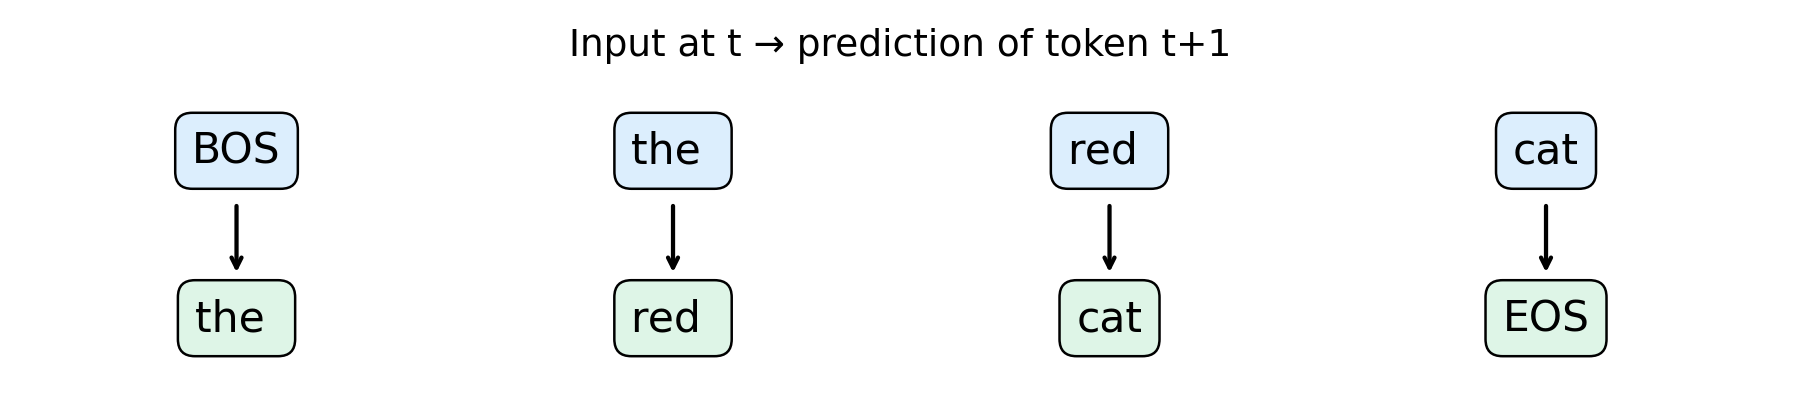

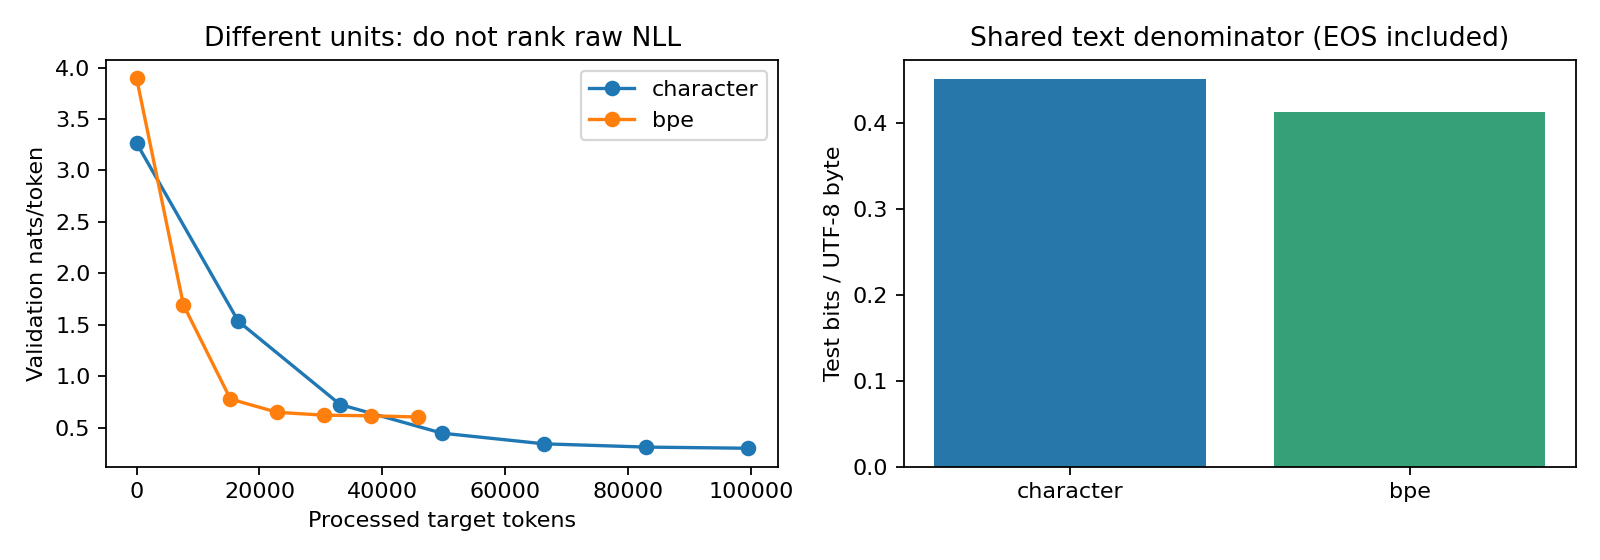

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。